# Predicción del nivel máximo del rio magdalena.

Este es un trabajo experimental en el cual se pondrá a prueba diversos métodos de machine learning para determinar que modelo según cierto criterios es mejor para predecir el nivel máximo del río Magdalena.

El río Magdalena tiene una extensión de 1.540 kilómetros y atraviesa hasta 13 departamentos del territorio colombiano. Su nivel se mide con sensores. *Este dataset fue extraído desde la página oficial de Datos Abiertos Colombia y se puede obtener en el siguiente enlace: [Dataset utilizado](https://www.datos.gov.co/Ambiente-y-Desarrollo-Sostenible/Nivel-M-ximo-del-Rio/vfth-yucv/explore/query/SELECT%20%60fechaobservacion%60%2C%20%60valorobservado%60%0AWHERE%20caseless_one_of%28%60codigoestacion%60%2C%20"0025027020"%29/page/filter).*

Tenemos una **serie de tiempo**: un sensor registró el nivel del agua en
distintos horarios. Los datos están en `Nivel_Máximo_del_Rio_20261026.csv` y cubren desde el 4 de octubre de 2004 hasta el 24 de octubre de 2026, de la estación EL BANCO - AUT (código 25027020).

según la [ficha del dataset](https://www.datos.gov.co/api/views/vfth-yucv.json), el nivel máximo es el punto más alto que alcanzó el agua durante una hora, en metros. Los datos son crudos, no validados por IDEAM por lo que puede cotener errores del sensor.

Este trabajo experimental es importante para la navegación ya que está depende de que el río tenga un nivel alto de agua, ademas la comunicación a las poblaciones cercanas a las orillas del río seria más eficiente.

Contamos con las suguientes variables:

| Variable | Qué es |
|---|---|
| FechaObservacion | Fecha y hora de la medición |
| ValorObservado | Nivel máximo del río en esa hora, en metros |

El objetivo de este trabajo es predecir el nivel máximo que tendrá el río en las próximas 8 h, 24 h, 3 días y 1 semana, a partir de las 6 lecturas más recientes.

## 1. Importación de librerías y configuración

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")


## 2. Carga del dataset

In [2]:
df_raw = pd.read_csv("Nivel_Máximo_del_Rio_20261026.csv")
df = df_raw.copy()

print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.info()
display(df.head())

Dimensiones: 105,428 filas x 2 columnas
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   FechaObservacion  105428 non-null  str  
 1   ValorObservado    105428 non-null  str  
dtypes: str(2)
memory usage: 1.6 MB


,FechaObservacion,ValorObservado
0,2019 Jun 28 10:08:00 PM,"7,44"
1,2015 Mar 11 04:37:00 PM,"4,83"
2,2018 Nov 13 01:42:00 AM,"8,71"
3,2017 Nov 06 03:56:00 PM,"6,66"
4,2017 Nov 21 01:39:00 PM,"5,8"


Nuestras variables se encuentra en el tipo de dato 'string', pasaremos la FechaObservacion a tipo datetime y el ValorObservado cambiaremos el separador "," por "." para convertirlo a tipo float.

In [3]:
df["ValorObservado"] = df["ValorObservado"].str.replace(",", ".")
df["ValorObservado"] = pd.to_numeric(df["ValorObservado"], errors="coerce")

print(f"Datos valor observado con errores al convertir: {df["ValorObservado"].isna().sum()}")

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce")

print(f"Datos fecha observada con errores al convertir: {df["FechaObservacion"].isna().sum()}")

df.info()

Datos valor observado con errores al convertir: 0
Datos fecha observada con errores al convertir: 0
<class 'pandas.DataFrame'>
RangeIndex: 105428 entries, 0 to 105427
Data columns (total 2 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   FechaObservacion  105428 non-null  datetime64[us]
 1   ValorObservado    105428 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 1.6 MB


## 3. Inspección inicial
Luego de modificar los tipos de datos se revisarán duplicados y valores faltantes

In [4]:
df_filtrado = df.sort_values("FechaObservacion").reset_index(drop=True)

filas_identicas = df_filtrado.duplicated().sum()

fechas_repetidas = df_filtrado.duplicated(subset=["FechaObservacion"]).sum()

conteo = df_filtrado["FechaObservacion"].value_counts()
conteo = conteo[conteo > 1]

print("Filas idénticas:", filas_identicas)
print("Filas con fecha repetida:", fechas_repetidas)
print("Fechas distintas que se repiten:", len(conteo))

df_filtrado[df_filtrado.duplicated(subset=["FechaObservacion"], keep=False)]

Filas idénticas: 6125
Filas con fecha repetida: 6125
Fechas distintas que se repiten: 5523


,FechaObservacion,ValorObservado
49248,2019-08-28 00:02:00,6.39
49249,2019-08-28 00:02:00,6.39
49250,2019-08-28 00:02:00,6.39
49251,2019-08-28 01:01:00,6.39
49252,2019-08-28 01:01:00,6.39
...,...,...
103717,2026-07-24 23:51:00,4.91
103718,2026-07-24 23:51:00,4.91
103719,2026-07-24 23:51:00,4.91
103720,2026-07-24 23:51:00,4.91


Hay 6125 filas que son copias exactas de otra fila (misma fecha y mismo valor), y están repartidas en 5523 fechas distintas

No se encontró ninguna misma fecha con valores diferentes.

Si se eliminaran las copias, quedarían 105.428 − 6125 = 99.303 filas.

In [5]:
df_unico = df_filtrado.drop_duplicates().reset_index(drop=True)

print("Antes:", df_filtrado.shape[0])
print("Después:", df_unico.shape[0])
print("Eliminadas:", df_filtrado.shape[0] - df_unico.shape[0])
print("Fechas que aún se repiten:", df_unico.duplicated(subset=["FechaObservacion"]).sum(), "\n")
print("Registros con valores nulos:")
df_unico.isnull().sum()

Antes: 105428
Después: 99303
Eliminadas: 6125
Fechas que aún se repiten: 0 

Registros con valores nulos:


FechaObservacion    0
ValorObservado      0
dtype: int64

### 3.1 Resumen de variables 

In [6]:
print("\nResumen de variables:")
display(df_unico.describe(include="all").T)


Resumen de variables:


,count,mean,min,25%,50%,75%,max,std
FechaObservacion,99303,2020-09-12 01:03:32.615993,2004-10-04 22:54:03,2017-12-18 17:19:00,2019-09-13 19:01:00,2024-07-02 23:00:00,2026-10-24 23:45:00,NaN
ValorObservado,99303.0,6.322265,0.0,5.1,6.27,6.96,164.0,9.498909


La mitad de los registros es de septiembre de 2019 en adelante, así que la mayoría de los datos son recientes.

Para el nivel, la media 6,32 m y la mediana 6,27 m son parecidas, y la mitad de los registros está entre 5,1 y 6,96 m. Pero el mínimo es 0 m, el máximo es 164 m y la desviación estándar 9,5 m es mayor que la misma media. Eso no cuadra con un río que normalmente está entre 4 y 10 m: hay valores raros que estiran la escala.

Mediciones fuera del rango graficado (0 o >12 m): 9,859 (9.93%)


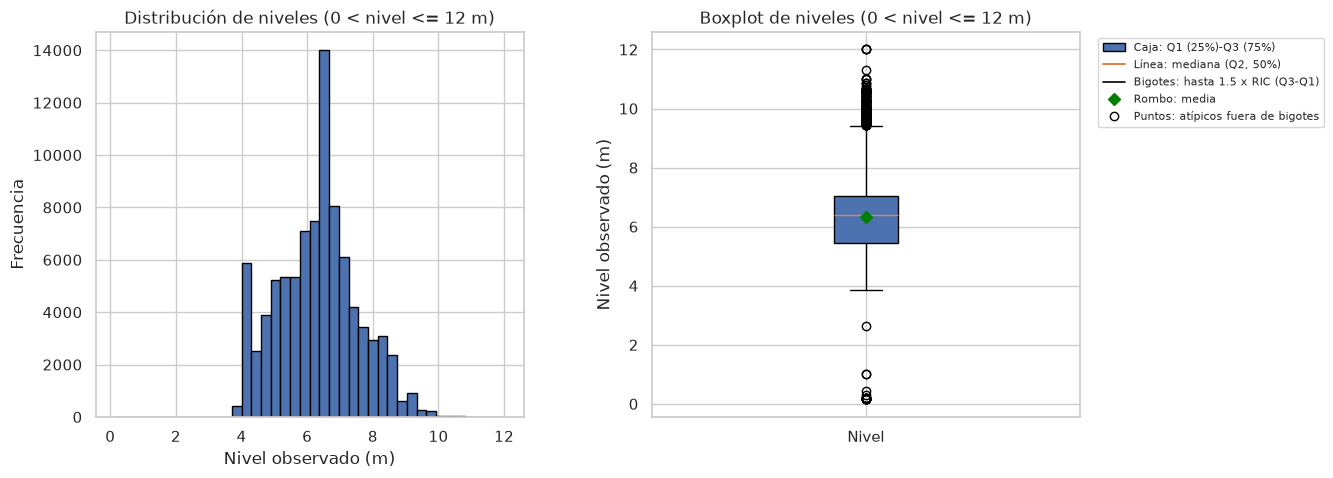

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

niveles = df_unico["ValorObservado"]
niveles_en_rango = niveles[(niveles > 0) & (niveles <= 12)]
fuera_de_rango = len(niveles) - len(niveles_en_rango)
print(f"Mediciones fuera del rango graficado (0 o >12 m): {fuera_de_rango:,} ({fuera_de_rango / len(niveles):.2%})")

fig, ejes = plt.subplots(1, 2, figsize=(16, 5))

ejes[0].hist(niveles_en_rango, bins=40, edgecolor="black")
ejes[0].set_title("Distribución de niveles (0 < nivel <= 12 m)")
ejes[0].set_xlabel("Nivel observado (m)")
ejes[0].set_ylabel("Frecuencia")

ejes[1].boxplot(
    niveles_en_rango,
    orientation="vertical",
    showmeans=True,
    patch_artist=True,
    meanprops={"marker": "D", "markerfacecolor": "green", "markeredgecolor": "green"},
)
ejes[1].set_title("Boxplot de niveles (0 < nivel <= 12 m)")
ejes[1].set_ylabel("Nivel observado (m)")
ejes[1].set_xticks([1], ["Nivel"])

elementos_leyenda = [
    Patch(facecolor="C0", edgecolor="black", label="Caja: Q1 (25%)-Q3 (75%)"),
    Line2D([0], [0], color="C1", linewidth=1.5, label="Línea: mediana (Q2, 50%)"),
    Line2D([0], [0], color="black", linewidth=1.2, label="Bigotes: hasta 1.5 x RIC (Q3-Q1)"),
    Line2D([0], [0], marker="D", color="green", linestyle="None", label="Rombo: media"),
    Line2D([0], [0], marker="o", markerfacecolor="white", markeredgecolor="black", linestyle="None", label="Puntos: atípicos fuera de bigotes"),
]
ejes[1].legend(handles=elementos_leyenda, loc="upper left", bbox_to_anchor=(1.03, 1), fontsize=8)

fig.subplots_adjust(right=0.74, wspace=0.3)
plt.show()

In [8]:
limite = 12

print("Valores iguales a 0:", (df_unico["ValorObservado"] == 0).sum())
print(f"Valores mayores a {limite}:", (df_unico["ValorObservado"] > limite).sum())

ceros = df_unico[df_unico["ValorObservado"] == 0]
print(ceros["FechaObservacion"].min(), ceros["FechaObservacion"].max())

display(df_unico.nlargest(15, "ValorObservado"))

Valores iguales a 0: 9420
Valores mayores a 12: 439
2017-10-07 08:52:00 2025-07-22 04:00:00


,FechaObservacion,ValorObservado
27645,2017-12-30 20:08:00,164.0
24131,2017-12-07 03:22:00,149.0
24507,2017-12-16 04:30:00,149.0
24514,2017-12-16 05:06:00,149.0
24613,2017-12-17 04:30:00,149.0
24619,2017-12-17 05:06:00,149.0
24652,2017-12-17 15:06:00,149.0
24662,2017-12-17 18:00:00,149.0
24704,2017-12-18 03:12:00,149.0
24711,2017-12-18 04:30:00,149.0


In [9]:
anomalos = df_unico[(df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)]

print("Total de valores raros:", len(anomalos))
print(f"Porcentaje del total: {len(anomalos) / len(df_unico):.2%}")

anomalos["FechaObservacion"].dt.year.value_counts().sort_index()

Total de valores raros: 9859
Porcentaje del total: 9.93%


FechaObservacion
2012       1
2017    3192
2018    6653
2024       7
2025       6
Name: count, dtype: int64

El histograma y el boxplot se enfocan en los niveles mayores que 0 y hasta 12 m. Así se amplía la zona donde se concentra la mayoría de las mediciones habituales, aproximadamente entre 4 y 10 m.

El corte de 12 m es exploratorio: ayuda a visualizar la distribución principal, pero no se ha confirmado como máximo físico del río ni como umbral oficial de calidad de IDEAM.

**Registros fuera del rango mostrado**

- 9.420 mediciones iguales a 0.
- 439 mediciones mayores que 12 m.
- Total: 9.859 registros (9,93 %).

Estos registros se excluyen de estos gráficos y del subconjunto validos, pero no se eliminaron de df_unico. Los puntos atípicos que aparecen dentro del rango tampoco se consideran errores automáticamente: el boxplot solo identifica observaciones alejadas de la distribución central.

Se observan valores desde 0 hasta 164 m. Aunque la ficha de IDEAM indica que la unidad es metros, también advierte que los datos son crudos y no han sido validados. Por eso, los extremos requieren revisión antes de clasificarlos como mediciones válidas o errores.

In [10]:
valores_mayores_12 = df_unico.loc[
    df_unico["ValorObservado"] > 12,
    ["FechaObservacion", "ValorObservado"],
].copy()
frecuencia_valores_altos = (
    valores_mayores_12["ValorObservado"]
    .value_counts()
    .rename_axis("nivel_m")
    .reset_index(name="registros")
)

ceros_en_crudo = (df_filtrado["ValorObservado"] == 0).sum()
ceros_deduplicados = (df_unico["ValorObservado"] == 0).sum()
ceros_duplicados_eliminados = ceros_en_crudo - ceros_deduplicados

print("Ceros en CSV cargado:", ceros_en_crudo)
print("Ceros tras quitar duplicados exactos:", ceros_deduplicados)
print("Ceros que eran duplicados exactos:", ceros_duplicados_eliminados)
print("Valores >12 m tras quitar duplicados:", len(valores_mayores_12))
display(frecuencia_valores_altos)

Ceros en CSV cargado: 9427
Ceros tras quitar duplicados exactos: 9420
Ceros que eran duplicados exactos: 7
Valores >12 m tras quitar duplicados: 439


,nivel_m,registros
0,149.00,384
1,131.00,26
2,126.00,6
3,13.00,3
4,26.00,3
5,32.00,2
6,136.00,2
7,38.00,2
8,125.00,2
9,76.00,2


In [11]:
ceros["FechaObservacion"].dt.to_period("M").value_counts().sort_index()


FechaObservacion
2017-10       3
2017-11      17
2017-12    3121
2018-01    6266
2024-11       1
2024-12       6
2025-03       1
2025-04       1
2025-06       2
2025-07       2
Freq: M, Name: count, dtype: int64

### Hallazgos sobre valores sospechosos

La ficha oficial de [Nivel Máximo del Río](https://www.datos.gov.co/api/views/vfth-yucv.json) indica que la unidad es metros y define el nivel máximo como el punto más alto registrado durante una hora. También advierte que los datos son crudos, no han sido validados por IDEAM y pueden contener errores de sensor. La ficha no establece 12 m como límite oficial ni define el valor 0 como código de error.

Después de quitar duplicados exactos hay 9.420 ceros y 439 valores mayores a 12 m. Los altos tienen 17 valores distintos: 149 m aparece 384 veces, 131 m 26 veces y 126 m seis veces. Se concentran en diciembre de 2017 y enero de 2018, Los valores de 0 m y los mayores a 12 m, no son mediciones que concuerden con el comportamiento normal de un río. fuera de esos dos meses casi no aparecen ceros (1 o 2 ceros por mes a finales de 2024 y en 2025, por lo cual estos valores atípicos serán considerados errores del sensor.

En el CSV cargado había 9.427 ceros; siete pertenecían a filas duplicadas exactas que se quitaron. Por eso `df_unico` conserva 9.420 ceros. El portal devuelve 9.427 ceros y 439 valores mayores a 12 para la estación en su conjunto, lo mismo que el csv antes de quitar los duplicados.

para la limpieza serán eliminados los valores en 0 además de los valores mayores a 12 porque los valores normales llegan hasta unos 11 m y de ahí saltan a 13, 26 y 149 m, ademas se observan unos valores entre 0 y 3 que representan un 0,02% de los datos, los cuales se mantendrán porque son muy pocas para cambiar los resultados.

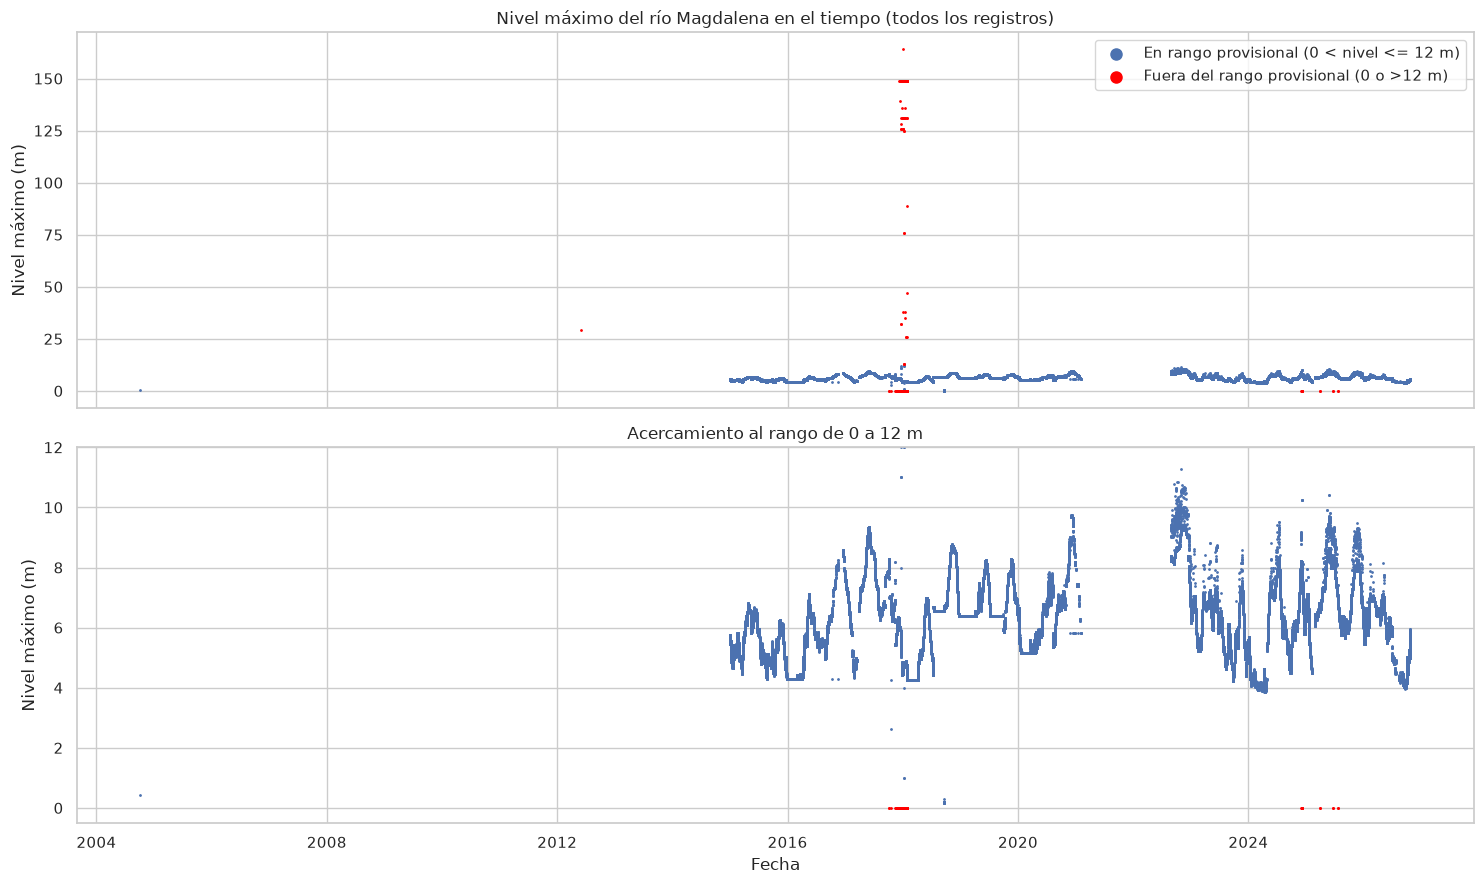

In [12]:
limite = 12
fuera_criterio = (df_unico["ValorObservado"] == 0) | (df_unico["ValorObservado"] > limite)
validos = df_unico[~fuera_criterio]
anomalos = df_unico[fuera_criterio]

fig, ejes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

ejes[0].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1, label="En rango provisional (0 < nivel <= 12 m)")
ejes[0].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red", label="Fuera del rango provisional (0 o >12 m)")
ejes[0].set_title("Nivel máximo del río Magdalena en el tiempo (todos los registros)")
ejes[0].set_ylabel("Nivel máximo (m)")
ejes[0].legend(markerscale=8)

ejes[1].scatter(validos["FechaObservacion"], validos["ValorObservado"], s=1)
ejes[1].scatter(anomalos["FechaObservacion"], anomalos["ValorObservado"], s=1, color="red")
ejes[1].set_ylim(-0.5, 12)
ejes[1].set_title("Acercamiento al rango de 0 a 12 m")
ejes[1].set_xlabel("Fecha")
ejes[1].set_ylabel("Nivel máximo (m)")

plt.tight_layout()
plt.show()

In [13]:
fechas_validas = validos["FechaObservacion"]

huecos = pd.DataFrame({
    "desde": fechas_validas.shift(1),
    "hasta": fechas_validas,
    "duracion": fechas_validas.diff()
})
huecos = huecos[huecos["duracion"] > pd.Timedelta(days=30)].sort_values("duracion", ascending=False)

display(huecos)

,desde,hasta,duracion
2,2004-10-04 22:54:03,2015-01-01 00:01:00,3740 days 01:06:57
60101,2021-02-02 11:01:00,2022-08-26 21:22:00,570 days 10:21:00


Podemos ver como antes del 2015 prácticamente no existen registro a excepción de 2 valores atípicos, ademas se identifica como existe un falta de registros entre el año 2021 y el año 2022.

Los puntos rojos en 0 están entre finales de 2017 y 2018, con datos válidos mezclados. No es un hueco completo, por eso no sale en la tabla. Hay unos pocos ceros más a finales de 2024 y 2025.
Los valores como 149 y 164 están todos en diciembre de 2017. Se ve una columna de puntos rojos en esa fecha.
Hay subidas y bajadas que se repiten cada año, entre unos 4 y 10 m. Es la estacionalidad que se puede observar ya que el nivel del río depende de la temporadas de lluvia y sequías del año.

## 4. Preparación para modelos

El entrenamiento parte únicamente de `filtrada.csv`, construida con registros deduplicados cuyo nivel cumple `0 < nivel <= 12 m`. Los niveles mayores a 12 m y los ceros no se usan en predictores ni objetivos del modelo. El corte de 12 m y el límite de 8 horas entre lecturas son decisiones exploratorias, no criterios oficiales de calidad del IDEAM.

El archivo contiene una fila por origen, los predictores y los objetivos de máximo observado para cuatro horizontes: 8 horas, 1 día, 3 días y 1 semana. Cada horizonte se entrena y evalúa por separado.

## Variables seleccionadas

Se conserva el grupo que obtuvo el mejor resultado preliminar: seis niveles recientes (`nivel_t` y cinco rezagos) y los cinco intervalos entre esas lecturas, para un total de 11 predictores. Se excluyen las variables cíclicas de mes y hora porque no mejoraron la evaluación preliminar.

## Separación 80/20

Para cada horizonte, los datos de `filtrada.csv` se ordenan por fecha y se toma como inicio de prueba el corte del 80 %. Se eliminan del entrenamiento los orígenes cuya ventana objetivo alcanza el comienzo de prueba, evitando que el entrenamiento use niveles del periodo de prueba. La prueba se reserva para reportar MAE y RMSE.

## 5. Construcción de `filtrada.csv`

Cada origen usa las seis lecturas válidas más recientes, con un intervalo máximo provisional de 8 horas entre lecturas. El objetivo es el máximo observado después del origen en `(t, t + h]`; si no hay lecturas dentro de esa ventana, el objetivo correspondiente queda vacío.

Esta celda genera **un solo archivo**, `filtrada.csv`: excluye siempre ceros y niveles mayores a 12 m, y contiene los 11 predictores seleccionados y cuatro objetivos (8 h, 24 h, 72 h y 168 h).

In [14]:
import numpy as np
import pandas as pd
from pathlib import Path

horizontes_horas = [8, 24, 72, 168]
numero_lecturas_entrada = 6
limite_hueco_entrada_horas = 8
ruta_filtrada = Path.cwd() / "filtrada.csv"

mascara_modelo = (
    df_unico["FechaObservacion"].notna()
    & df_unico["ValorObservado"].gt(0)
    & df_unico["ValorObservado"].le(12)
)
df_modelo = (
    df_unico.loc[mascara_modelo]
    .sort_values("FechaObservacion")
    .reset_index(drop=True)
    .copy()
)
print("Registros usados (0 < nivel <= 12 m):", len(df_modelo))

fechas = df_modelo["FechaObservacion"]
fechas_ns = fechas.to_numpy(dtype="datetime64[ns]").view("int64")
niveles_array = df_modelo["ValorObservado"].to_numpy(dtype=float)

X = pd.DataFrame(index=df_modelo.index)
columnas_nivel = ["nivel_t"] + [
    f"nivel_t_menos_{rezago}"
    for rezago in range(1, numero_lecturas_entrada)
]
for rezago, nombre_columna in enumerate(columnas_nivel):
    X[nombre_columna] = df_modelo["ValorObservado"].shift(rezago)

intervalo_horas = fechas.diff().dt.total_seconds() / 3600
columnas_intervalo = []
for rezago in range(numero_lecturas_entrada - 1):
    nombre_columna = f"horas_entre_t_menos_{rezago}_y_t_menos_{rezago + 1}"
    X[nombre_columna] = intervalo_horas.shift(rezago)
    columnas_intervalo.append(nombre_columna)

columnas_predictores = columnas_nivel + columnas_intervalo
historial_completo = (
    X[columnas_predictores].notna().all(axis=1)
    & X[columnas_intervalo].le(limite_hueco_entrada_horas).all(axis=1)
)
print("Orígenes con historial incompleto o salto >8 h:",
      int((~historial_completo).sum()))

objetivos = pd.DataFrame(index=df_modelo.index)
resumen_horizontes = []
for horizonte in horizontes_horas:
    objetivo = np.full(len(df_modelo), np.nan, dtype=float)
    duracion_ns = pd.Timedelta(hours=horizonte).value

    for posicion, fecha_ns in enumerate(fechas_ns):
        inicio = np.searchsorted(fechas_ns, fecha_ns, side="right")
        fin = np.searchsorted(fechas_ns, fecha_ns + duracion_ns, side="right")
        if inicio < fin:
            objetivo[posicion] = niveles_array[inicio:fin].max()

    nombre_objetivo = f"maximo_observado_proximas_{horizonte}h"
    objetivos[nombre_objetivo] = objetivo
    filas_con_objetivo = historial_completo & objetivos[nombre_objetivo].notna()
    resumen_horizontes.append({
        "horizonte_horas": horizonte,
        "muestras": int(filas_con_objetivo.sum()),
        "origenes_sin_lectura_futura": int(
            (historial_completo & objetivos[nombre_objetivo].isna()).sum()
        ),
    })

mascara_exportacion = historial_completo & objetivos.notna().any(axis=1)
filtrada = pd.concat(
    [fechas.rename("fecha_origen"), X[columnas_predictores], objetivos],
    axis=1,
).loc[mascara_exportacion].reset_index(drop=True)
filtrada.to_csv(ruta_filtrada, index=False, date_format="%Y-%m-%d %H:%M:%S")

print("Archivo generado:", ruta_filtrada)
print("Filas:", len(filtrada), "| Predictores:", len(columnas_predictores))
display(pd.DataFrame(resumen_horizontes))
display(filtrada.head())

Registros usados (0 < nivel <= 12 m): 89444
Orígenes con historial incompleto o salto >8 h: 1040
Archivo generado: /workspaces/machine_learnig_rio_magdalena/filtrada.csv
Filas: 88399 | Predictores: 11


,horizonte_horas,muestras,origenes_sin_lectura_futura
0,8,88230,174
1,24,88351,53
2,72,88388,16
3,168,88399,5


,fecha_origen,nivel_t,nivel_t_menos_1,nivel_t_menos_2,nivel_t_menos_3,nivel_t_menos_4,nivel_t_menos_5,horas_entre_t_menos_0_y_t_menos_1,horas_entre_t_menos_1_y_t_menos_2,horas_entre_t_menos_2_y_t_menos_3,horas_entre_t_menos_3_y_t_menos_4,horas_entre_t_menos_4_y_t_menos_5,maximo_observado_proximas_8h,maximo_observado_proximas_24h,maximo_observado_proximas_72h,maximo_observado_proximas_168h
0,2015-01-01 05:50:00,5.73,5.73,5.72,5.73,5.72,5.72,1.350000,1.283333,0.333333,1.683333,1.166667,5.75,5.76,5.76,5.76
1,2015-01-01 06:45:00,5.73,5.73,5.73,5.72,5.73,5.72,0.916667,1.350000,1.283333,0.333333,1.683333,5.75,5.76,5.76,5.76
2,2015-01-01 07:12:00,5.73,5.73,5.73,5.73,5.72,5.73,0.450000,0.916667,1.350000,1.283333,0.333333,5.75,5.76,5.76,5.76
3,2015-01-01 08:55:00,5.73,5.73,5.73,5.73,5.73,5.72,1.716667,0.450000,0.916667,1.350000,1.283333,5.75,5.76,5.76,5.76
4,2015-01-01 09:35:00,5.74,5.73,5.73,5.73,5.73,5.73,0.666667,1.716667,0.450000,0.916667,1.350000,5.76,5.76,5.76,5.76


## 6. Preparación y partición temporal

Después de generar `filtrada.csv`, esta celda crea para cada horizonte la partición cronológica 80/20 y purga del entrenamiento los orígenes cuya ventana objetivo alcanza el inicio de prueba. También define los pliegues temporales purgados que reutilizan Ridge, el árbol y Random Forest.

In [15]:
from sklearn.model_selection import TimeSeriesSplit

ruta_filtrada = Path.cwd() / "filtrada.csv"
datos_filtrados = pd.read_csv(ruta_filtrada, parse_dates=["fecha_origen"])
columnas_predictores = [
    "nivel_t",
    *[f"nivel_t_menos_{rezago}" for rezago in range(1, numero_lecturas_entrada)],
    *[
        f"horas_entre_t_menos_{rezago}_y_t_menos_{rezago + 1}"
        for rezago in range(numero_lecturas_entrada - 1)
    ],
]
particiones_por_horizonte = {}
resultados_comparacion = pd.DataFrame(
    columns=["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]
)

for horizonte in horizontes_horas:
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    datos = (
        datos_filtrados
        .dropna(subset=[columna_objetivo])
        .sort_values("fecha_origen")
        .reset_index(drop=True)
    )
    posicion_corte = int(len(datos) * 0.8)
    fecha_inicio_prueba = datos.loc[posicion_corte, "fecha_origen"]
    duracion_horizonte = pd.Timedelta(hours=horizonte)
    mascara_entrenamiento = (
        (datos["fecha_origen"] < fecha_inicio_prueba)
        & (datos["fecha_origen"] + duracion_horizonte < fecha_inicio_prueba)
    )
    entrenamiento = datos.loc[mascara_entrenamiento].reset_index(drop=True)
    prueba = datos.loc[datos["fecha_origen"] >= fecha_inicio_prueba].reset_index(drop=True)
    if entrenamiento.empty or prueba.empty:
        raise ValueError(f"No hay suficientes datos para el horizonte de {horizonte} h.")

    particiones_por_horizonte[horizonte] = {
        "entrenamiento": entrenamiento,
        "prueba": prueba,
        "fecha_inicio_prueba": fecha_inicio_prueba,
    }
    print(
        f"Horizonte {horizonte} h | corte: {fecha_inicio_prueba} | "
        f"entrenamiento: {len(entrenamiento)} | prueba: {len(prueba)} | "
        f"purgadas: {int((datos['fecha_origen'] < fecha_inicio_prueba).sum() - len(entrenamiento))}"
    )

fechas_observadas_ns = (
    df_modelo["FechaObservacion"]
    .to_numpy(dtype="datetime64[ns]")
    .view("int64")
)
niveles_observados = df_modelo["ValorObservado"].to_numpy(dtype=float)


def crear_pliegues_temporales(entrenamiento, horizonte, n_splits=3):
    duracion = pd.Timedelta(hours=horizonte)
    pliegues = []
    for indices_entrenamiento, indices_validacion in TimeSeriesSplit(
        n_splits=n_splits
    ).split(entrenamiento):
        inicio_validacion = entrenamiento.iloc[indices_validacion]["fecha_origen"].min()
        fechas_entrenamiento = entrenamiento.iloc[indices_entrenamiento]["fecha_origen"]
        indices_entrenamiento = indices_entrenamiento[
            (fechas_entrenamiento + duracion < inicio_validacion).to_numpy()
        ]
        if len(indices_entrenamiento) == 0:
            raise ValueError(f"Pliegue temporal vacío: horizonte {horizonte} h")
        pliegues.append((indices_entrenamiento, indices_validacion))
    return pliegues


Horizonte 8 h | corte: 2025-01-26 16:56:00 | entrenamiento: 70570 | prueba: 17646 | purgadas: 14
Horizonte 24 h | corte: 2025-01-26 11:56:00 | entrenamiento: 70631 | prueba: 17671 | purgadas: 49
Horizonte 72 h | corte: 2025-01-26 12:43:00 | entrenamiento: 70568 | prueba: 17678 | purgadas: 142
Horizonte 168 h | corte: 2025-01-26 12:11:00 | entrenamiento: 70390 | prueba: 17680 | purgadas: 329


## 7. Líneas base de referencia (Heurísticas de persistencia)

Antes de entrenar modelos de aprendizaje automático, se definen dos líneas base no paramétricas de referencia basadas en persistencia e hidrología:
1. **`ultimo_nivel`**: Asume que el nivel máximo futuro será idéntico a la última medición disponible (`nivel_t`).
2. **`maximo_pasado_mismo_horizonte`**: Asume que el nivel máximo futuro será igual al nivel máximo observado en una ventana pasada de igual duración $(t - h, t]$.

Cualquier modelo de aprendizaje automático (lineal o basado en árboles) debe superar holgadamente estas heurísticas para justificar su complejidad operativa.


In [ ]:
resultados_lineas_base = []

for horizonte, particion in particiones_por_horizonte.items():
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    real = prueba[columna_objetivo].to_numpy(dtype=float)

    # Línea base 1: Repetir el último nivel observado
    pred_ultimo = prueba["nivel_t"].to_numpy(dtype=float)

    # Línea base 2: Máximo observado en una ventana previa de igual duración (t - h, t]
    fechas_prueba_ns = prueba["fecha_origen"].to_numpy(dtype="datetime64[ns]").view("int64")
    inicio_indices = np.searchsorted(
        fechas_observadas_ns,
        fechas_prueba_ns - pd.Timedelta(hours=horizonte).value,
        side="right",
    )
    fin_indices = np.searchsorted(fechas_observadas_ns, fechas_prueba_ns, side="right")
    pred_maximo_pasado = np.array([
        niveles_observados[inicio:fin].max() if inicio < fin else np.nan
        for inicio, fin in zip(inicio_indices, fin_indices)
    ])

    predicciones_base = {
        "ultimo_nivel": pred_ultimo,
        "maximo_pasado_mismo_horizonte": pred_maximo_pasado,
    }

    for nombre_modelo, prediccion in predicciones_base.items():
        resultados_lineas_base.append({
            "modelo": nombre_modelo,
            "horizonte_horas": horizonte,
            "muestras_prueba": len(prueba),
            "MAE_m": mean_absolute_error(real, prediccion),
            "RMSE_m": mean_squared_error(real, prediccion) ** 0.5,
        })

resultados_lineas_base = pd.DataFrame(resultados_lineas_base)
display(resultados_lineas_base)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_lineas_base[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


## 8. Regresión lineal regularizada (Ridge)

### 8.1 Modelo inicial de Ridge

Se implementa una regresión lineal con regularización $L_2$ (Ridge). Para garantizar que las variables con diferentes escalas y unidades (niveles en metros vs. intervalos en horas) reciban una penalización equitativa, se integra un `StandardScaler` dentro de un `Pipeline` de scikit-learn.

En esta etapa inicial, se ajusta el modelo con su hiperparámetro de penalización por defecto ($\\alpha = 1.0$) y con intercepto (`fit_intercept = True`) para cada uno de los cuatro horizontes de tiempo, evaluando su desempeño directamente en la partición independiente de prueba (20 %).


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

resultados_ridge_inicial = []
modelos_ridge_iniciales = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"]
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"

    modelo = Pipeline([
        ("escalador", StandardScaler()),
        ("ridge", Ridge(alpha=1.0, fit_intercept=True, random_state=42)),
    ])
    modelo.fit(entrenamiento[columnas_predictores], entrenamiento[columna_objetivo])
    prediccion = modelo.predict(prueba[columnas_predictores])
    real = prueba[columna_objetivo]
    modelos_ridge_iniciales[horizonte] = modelo

    resultados_ridge_inicial.append({
        "modelo": "ridge_inicial",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(real, prediccion),
        "RMSE_m": mean_squared_error(real, prediccion) ** 0.5,
    })

resultados_ridge_inicial = pd.DataFrame(resultados_ridge_inicial)
display(resultados_ridge_inicial)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_ridge_inicial[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


### 8.2 Búsqueda de hiperparámetros de Ridge (Fase Coarse - GridSearchCV)

Siguiendo la estrategia **Coarse-to-Fine**, en esta primera etapa se realiza una exploración amplia (*coarse*) sobre el pipeline de Ridge evaluando **58 combinaciones por horizonte**:
- `ridge__alpha`: 29 valores en escala logarítmica continua cubriendo 14 órdenes de magnitud entre $10^{-7}$ y $10^{7}$ (`np.logspace(-7, 7, 29)`).
- `ridge__fit_intercept`: `[True, False]`.

La validación cruzada utiliza los tres pliegues temporales purgados (`crear_pliegues_temporales`). Esta búsqueda identifica de forma global la escala de regularización óptima para cada horizonte. Posteriormente, los resultados permitirán acotar una búsqueda fina (*fine*) en el rango más prometedor.


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipeline_ridge = Pipeline([
    ("escalador", StandardScaler()),
    ("ridge", Ridge(random_state=42)),
])
parametros_ridge = {
    "ridge__alpha": np.logspace(-7, 7, 29),
    "ridge__fit_intercept": [True, False],
}
resultados_busqueda_ridge = []
resultados_ridge_ajustado = []
modelos_ridge_ajustados = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"]
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    busqueda = GridSearchCV(
        pipeline_ridge,
        param_grid=parametros_ridge,
        scoring="neg_mean_absolute_error",
        cv=crear_pliegues_temporales(entrenamiento, horizonte),
        n_jobs=-1,
    )
    busqueda.fit(entrenamiento[columnas_predictores], entrenamiento[columna_objetivo])
    modelo = busqueda.best_estimator_
    prediccion = modelo.predict(prueba[columnas_predictores])
    real = prueba[columna_objetivo]
    modelos_ridge_ajustados[horizonte] = modelo

    for parametros, mae_cv in zip(
        busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
    ):
        resultados_busqueda_ridge.append({
            "horizonte_horas": horizonte,
            "alpha": parametros["ridge__alpha"],
            "fit_intercept": parametros["ridge__fit_intercept"],
            "MAE_CV_m": mae_cv,
        })

    resultados_ridge_ajustado.append({
        "modelo": "ridge_ajustado",
        "horizonte_horas": horizonte,
        "alpha": busqueda.best_params_["ridge__alpha"],
        "fit_intercept": busqueda.best_params_["ridge__fit_intercept"],
        "muestras_prueba": len(prueba),
        "MAE_CV_m": -busqueda.best_score_,
        "MAE_prueba_m": mean_absolute_error(real, prediccion),
        "RMSE_prueba_m": mean_squared_error(real, prediccion) ** 0.5,
    })

resultados_busqueda_ridge = pd.DataFrame(resultados_busqueda_ridge)
resultados_ridge_ajustado = pd.DataFrame(resultados_ridge_ajustado)

configuraciones_ridge_top = resultados_busqueda_ridge.copy()
configuraciones_ridge_top["configuracion"] = configuraciones_ridge_top.apply(
    lambda fila: f"alpha={fila['alpha']:.1e}, intercept={fila['fit_intercept']}",
    axis=1,
)

display(
    resultados_busqueda_ridge.sort_values(
        ["horizonte_horas", "MAE_CV_m"]
    ).groupby("horizonte_horas").head(5)
)
display(resultados_ridge_ajustado)

fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
for eje, (horizonte, candidatos) in zip(
    ejes.flat, configuraciones_ridge_top.groupby("horizonte_horas")
):
    mejores = candidatos.nsmallest(10, "MAE_CV_m").sort_values("MAE_CV_m")
    eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
    eje.invert_yaxis()
    eje.set_title(f"Ridge (Coarse) - Horizonte {horizonte} h")
    eje.set_xlabel("MAE de validación (m), menor es mejor")
    eje.set_ylabel("Combinación de hiperparámetros")

fig.tight_layout()
plt.show()

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_ridge_ajustado.rename(columns={
            "MAE_prueba_m": "MAE_m",
            "RMSE_prueba_m": "RMSE_m",
        })[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


## 9. Árbol de decisión (Decision Tree)

### 9.1 Modelo inicial de Árbol de decisión

Se entrena un árbol de decisión individual (`DecisionTreeRegressor`) para modelar relaciones no lineales e interacciones complejas entre los niveles observados y los intervalos transcurridos.

Como configuración inicial se establecen restricciones conservadoras para mitigar el sobreajuste propio de árboles sin podar:
- `max_depth = 6` (profundidad máxima)
- `min_samples_leaf = 20` (mínimo de muestras por nodo terminal)
- `random_state = 42`

El modelo inicial se evalúa en el 20 % de prueba para cada uno de los cuatro horizontes temporales.


In [ ]:
from sklearn.tree import DecisionTreeRegressor

resultados_arbol_inicial = []
modelos_arbol_iniciales = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"]
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"

    modelo = DecisionTreeRegressor(
        max_depth=6,
        min_samples_leaf=20,
        random_state=42,
    )
    modelo.fit(entrenamiento[columnas_predictores], entrenamiento[columna_objetivo])
    prediccion = modelo.predict(prueba[columnas_predictores])
    real = prueba[columna_objetivo]
    modelos_arbol_iniciales[horizonte] = modelo

    resultados_arbol_inicial.append({
        "modelo": "arbol_decision_inicial",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(real, prediccion),
        "RMSE_m": mean_squared_error(real, prediccion) ** 0.5,
    })

resultados_arbol_inicial = pd.DataFrame(resultados_arbol_inicial)
display(resultados_arbol_inicial)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_arbol_inicial[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


### 9.2 Búsqueda de hiperparámetros del Árbol de decisión (Fase Coarse - GridSearchCV)

Siguiendo la estrategia **Coarse-to-Fine**, se realiza una exploración amplia sobre la arquitectura del árbol individual evaluando **210 combinaciones por horizonte**:
- `max_depth`: `[4, 6, 8, 10, 14, 18, None]` (cubre desde estructuras podadas hasta crecimiento no restringido).
- `min_samples_leaf`: `[5, 10, 20, 40, 80]` (regula la granularidad terminal y mitigación de ruido).
- `min_samples_split`: `[2, 10, 30]` (sensibilidad para bifurcación interna).
- `criterion`: `["squared_error", "friedman_mse"]` (criterios cuadráticos eficientes y numéricamente estables).

La búsqueda se ejecuta con los tres pliegues temporales purgados (`crear_pliegues_temporales`) y selección por MAE (`neg_mean_absolute_error`). Esta malla mapea el compromiso sesgo-varianza del árbol en aproximadamente 1 minuto.


In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

parametros_arbol = {
    "max_depth": [4, 6, 8, 10, 14, 18, None],
    "min_samples_leaf": [5, 10, 20, 40, 80],
    "min_samples_split": [2, 10, 30],
    "criterion": ["squared_error", "friedman_mse"],
}
resultados_busqueda_arbol = []
resultados_arbol_ajustado = []
modelos_arbol_ajustados = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"]
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    busqueda = GridSearchCV(
        DecisionTreeRegressor(random_state=42),
        param_grid=parametros_arbol,
        scoring="neg_mean_absolute_error",
        cv=crear_pliegues_temporales(entrenamiento, horizonte),
        n_jobs=-1,
    )
    busqueda.fit(entrenamiento[columnas_predictores], entrenamiento[columna_objetivo])
    modelo = busqueda.best_estimator_
    prediccion = modelo.predict(prueba[columnas_predictores])
    real = prueba[columna_objetivo]
    modelos_arbol_ajustados[horizonte] = modelo

    for parametros, mae_cv in zip(
        busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
    ):
        resultados_busqueda_arbol.append({
            "horizonte_horas": horizonte,
            **parametros,
            "MAE_CV_m": mae_cv,
        })

    resultados_arbol_ajustado.append({
        "modelo": "arbol_decision_ajustado",
        "horizonte_horas": horizonte,
        **busqueda.best_params_,
        "muestras_prueba": len(prueba),
        "MAE_CV_m": -busqueda.best_score_,
        "MAE_prueba_m": mean_absolute_error(real, prediccion),
        "RMSE_prueba_m": mean_squared_error(real, prediccion) ** 0.5,
    })

resultados_busqueda_arbol = pd.DataFrame(resultados_busqueda_arbol)
resultados_arbol_ajustado = pd.DataFrame(resultados_arbol_ajustado)

configuraciones_arbol_top = resultados_busqueda_arbol.copy()
configuraciones_arbol_top["configuracion"] = configuraciones_arbol_top.apply(
    lambda fila: (
        f"prof={fila['max_depth']}, hoja={fila['min_samples_leaf']}, "
        f"split={fila['min_samples_split']}, crit={fila['criterion']}"
    ),
    axis=1,
)

display(
    resultados_busqueda_arbol.sort_values(
        ["horizonte_horas", "MAE_CV_m"]
    ).groupby("horizonte_horas").head(5)
)
display(resultados_arbol_ajustado)

fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
for eje, (horizonte, candidatos) in zip(
    ejes.flat, configuraciones_arbol_top.groupby("horizonte_horas")
):
    mejores = candidatos.nsmallest(10, "MAE_CV_m").sort_values("MAE_CV_m")
    eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
    eje.invert_yaxis()
    eje.set_title(f"Árbol de Decisión (Coarse) - Horizonte {horizonte} h")
    eje.set_xlabel("MAE de validación (m), menor es mejor")
    eje.set_ylabel("Combinación de hiperparámetros")

fig.tight_layout()
plt.show()

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_arbol_ajustado.rename(columns={
            "MAE_prueba_m": "MAE_m",
            "RMSE_prueba_m": "RMSE_m",
        })[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


## 10. Bosque aleatorio (Random Forest)

### 10.1 Modelo inicial de Random Forest

Se entrena un ensamble de árboles mediante `RandomForestRegressor`. El ensamble promedia múltiples árboles entrenados sobre submuestras generadas mediante *bootstrap* y selección aleatoria de variables por división, reduciendo notablemente la varianza del estimador y amortiguando el sobreajuste.

La configuración base inicial utiliza hiperparámetros estables y robustos:
- `n_estimators = 100` (100 árboles)
- `max_depth = 16`
- `min_samples_leaf = 5`
- `random_state = 42`
- `n_jobs = -1`

Se entrena y evalúa en la partición independiente de prueba (20 %) para cada horizonte temporal.


In [ ]:
from sklearn.ensemble import RandomForestRegressor

resultados_random_forest_inicial = []
modelos_random_forest_iniciales = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"]
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"

    modelo = RandomForestRegressor(
        n_estimators=100,
        max_depth=16,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1,
    )
    modelo.fit(entrenamiento[columnas_predictores], entrenamiento[columna_objetivo])
    prediccion = modelo.predict(prueba[columnas_predictores])
    real = prueba[columna_objetivo]
    modelos_random_forest_iniciales[horizonte] = modelo

    resultados_random_forest_inicial.append({
        "modelo": "random_forest_inicial",
        "horizonte_horas": horizonte,
        "muestras_prueba": len(prueba),
        "MAE_m": mean_absolute_error(real, prediccion),
        "RMSE_m": mean_squared_error(real, prediccion) ** 0.5,
    })

resultados_random_forest_inicial = pd.DataFrame(resultados_random_forest_inicial)
display(resultados_random_forest_inicial)

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_random_forest_inicial[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


### 10.2 Búsqueda de hiperparámetros de Random Forest (Fase Coarse - GridSearchCV)

Siguiendo la estrategia **Coarse-to-Fine**, en esta primera fase se diseña una exploración amplia que explora representativamente el espacio de búsqueda sin exceder el presupuesto computacional (calibrada para completarse en **~6 a 9 minutos** en procesadores modernos multihilo como el Core i5-12500).

Se evalúan **120 combinaciones por horizonte** (3 pliegues temporales = 360 ajustes de bosque por horizonte, 1.440 ajustes en total):
- `n_estimators`: `[60, 120]` (evalúa si una densidad intermedia de árboles es suficiente o si requiere mayor agregación).
- `max_depth`: `[6, 10, 14, 18, None]` (amplio espectro desde profundidad moderada hasta divisiones completas).
- `min_samples_leaf`: `[2, 5, 15, 30]` (evalúa la sensibilidad de ajuste fino vs. generalización robusta).
- `max_features`: `["sqrt", 0.6, 1.0]` (explora descorrelación estricta $\approx 3$ variables, subespacio intermedio $\approx 7$ variables, y todas las 11 variables).

La búsqueda se ejecuta con los pliegues temporales purgados (`crear_pliegues_temporales`) y selección por MAE (`neg_mean_absolute_error`). Tras la ejecución, se visualizarán las mejores regiones para la subsecuente fase de afinamiento fino.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

parametros_random_forest = {
    "n_estimators": [60, 120],
    "max_depth": [6, 10, 14, 18, None],
    "min_samples_leaf": [2, 5, 15, 30],
    "max_features": ["sqrt", 0.6, 1.0],
}
resultados_busqueda_random_forest = []
resultados_random_forest_ajustado = []
modelos_random_forest_ajustados = {}

for horizonte, particion in particiones_por_horizonte.items():
    entrenamiento = particion["entrenamiento"]
    prueba = particion["prueba"]
    columna_objetivo = f"maximo_observado_proximas_{horizonte}h"
    busqueda = GridSearchCV(
        RandomForestRegressor(random_state=42, n_jobs=1),
        param_grid=parametros_random_forest,
        scoring="neg_mean_absolute_error",
        cv=crear_pliegues_temporales(entrenamiento, horizonte),
        n_jobs=-1,
    )
    busqueda.fit(entrenamiento[columnas_predictores], entrenamiento[columna_objetivo])
    modelo = busqueda.best_estimator_
    prediccion = modelo.predict(prueba[columnas_predictores])
    real = prueba[columna_objetivo]
    modelos_random_forest_ajustados[horizonte] = modelo

    for parametros, mae_cv in zip(
        busqueda.cv_results_["params"], -busqueda.cv_results_["mean_test_score"]
    ):
        resultados_busqueda_random_forest.append({
            "horizonte_horas": horizonte,
            **parametros,
            "MAE_CV_m": mae_cv,
        })

    resultados_random_forest_ajustado.append({
        "modelo": "random_forest_ajustado",
        "horizonte_horas": horizonte,
        **busqueda.best_params_,
        "muestras_prueba": len(prueba),
        "MAE_CV_m": -busqueda.best_score_,
        "MAE_prueba_m": mean_absolute_error(real, prediccion),
        "RMSE_prueba_m": mean_squared_error(real, prediccion) ** 0.5,
    })

resultados_busqueda_random_forest = pd.DataFrame(
    resultados_busqueda_random_forest
)
resultados_random_forest_ajustado = pd.DataFrame(
    resultados_random_forest_ajustado
)

configuraciones_random_forest_top = resultados_busqueda_random_forest.copy()
configuraciones_random_forest_top["configuracion"] = (
    configuraciones_random_forest_top.apply(
        lambda fila: (
            f"arboles={fila['n_estimators']}, prof={fila['max_depth']}, "
            f"hoja={fila['min_samples_leaf']}, feat={fila['max_features']}"
        ),
        axis=1,
    )
)

display(
    resultados_busqueda_random_forest.sort_values(
        ["horizonte_horas", "MAE_CV_m"]
    ).groupby("horizonte_horas").head(5)
)
display(resultados_random_forest_ajustado)

fig, ejes = plt.subplots(2, 2, figsize=(16, 10))
for eje, (horizonte, candidatos) in zip(
    ejes.flat, configuraciones_random_forest_top.groupby("horizonte_horas")
):
    mejores = candidatos.nsmallest(10, "MAE_CV_m").sort_values("MAE_CV_m")
    eje.barh(mejores["configuracion"], mejores["MAE_CV_m"])
    eje.invert_yaxis()
    eje.set_title(f"Random Forest (Coarse) - Horizonte {horizonte} h")
    eje.set_xlabel("MAE de validación (m), menor es mejor")
    eje.set_ylabel("Combinación de hiperparámetros")

fig.tight_layout()
plt.show()

resultados_comparacion = pd.concat(
    [
        resultados_comparacion,
        resultados_random_forest_ajustado.rename(columns={
            "MAE_prueba_m": "MAE_m",
            "RMSE_prueba_m": "RMSE_m",
        })[["modelo", "horizonte_horas", "muestras_prueba", "MAE_m", "RMSE_m"]],
    ],
    ignore_index=True,
)
display(resultados_comparacion.sort_values(["horizonte_horas", "MAE_m"]))


## 11. Comparación general y consolidación de modelos

Esta sección consolida las métricas de prueba de todas las aproximaciones evaluadas:
- **Líneas base heurísticas**: `ultimo_nivel`, `maximo_pasado_mismo_horizonte`.
- **Modelos iniciales**: `ridge_inicial`, `arbol_decision_inicial`, `random_forest_inicial`.
- **Modelos optimizados (GridSearchCV)**: `ridge_ajustado`, `arbol_decision_ajustado`, `random_forest_ajustado`.

A continuación, se presenta la tabla general clasificada por horizonte de pronóstico y MAE, junto con un gráfico comparativo del error medio absoluto (MAE) en función del horizonte temporal.


In [ ]:
# Tabla consolidada ordenada por horizonte y desempeño (menor MAE)
tabla_final = resultados_comparacion.sort_values(
    ["horizonte_horas", "MAE_m"]
).reset_index(drop=True)
display(tabla_final)

# Gráfico comparativo de MAE por horizonte entre todos los modelos evaluados
plt.figure(figsize=(14, 7))
sns.barplot(
    data=tabla_final,
    x="horizonte_horas",
    y="MAE_m",
    hue="modelo",
    palette="tab10",
)
plt.title("Comparativa de Desempeño (MAE en Prueba) por Horizonte de Predicción", fontsize=14)
plt.xlabel("Horizonte de Predicción (horas)", fontsize=12)
plt.ylabel("Error Absoluto Medio - MAE (metros)", fontsize=12)
plt.legend(title="Modelo / Heurística", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()
